# Customer Churn Prediction
**Supervised Machine Learning Project**

In this project, we analyze customer data from a telecom company to predict whether a customer will stop using the service (churn).

---
### Notebook Structure:
1. `01_business_understanding`
2. `02_load_and_eda`
3. `03_split_and_preprocessing`
4. `04_baseline`
5. `05_model_comparison`
6. `06_tuning`
7. `07_final_evaluation`
8. `08_business_recommendations`

---
## 01_business_understanding

### Task 1: Understand the Business Problem

**1. Problem Description (in 3–5 sentences):**
Customer churn happens when subscribers cancel their telecom service. Acquiring new customers is much more expensive than keeping current ones. By analyzing customer account and service information, we can build a machine learning model to predict which customers are likely to leave. This allows the company to take action early and offer incentives to keep them.

**2. Target Column & Classification Problem:**
- **Target column:** `Churn` (Yes or No).
- **Why this is a classification problem:** We are predicting a categorical outcome (whether a customer leaves or stays), which makes this a binary classification problem.

**3. Two Examples of How the Business Can Use Predictions:**
- **Targeted Promotions:** Offer discounts or free add-ons to customers identified as high risk of churning before they cancel.
- **Customer Support Outreach:** Have support representatives call at-risk customers to solve any service complaints or technical problems.

**4. Why Missing a Likely Churner is Costly:**
A **False Negative** means the model predicted the customer would stay, but they actually left. This is very costly because the company loses that customer's recurring monthly payments and must spend a lot of money to find a replacement customer.

---
## 02_load_and_eda

### Task 2: Load and Explore the Data

In [2]:
# 5. Load the CSV using pandas, show first five rows and shape
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Load data
df = pd.read_csv('/content/Telco-Customer-Churn.csv')

print("Dataset Shape:", df.shape)
df.head()

Dataset Shape: (7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [3]:
# 6. Identify numerical, categorical, and identifier columns
identifier_col = ['customerID']
target_col = 'Churn'

# Note: TotalCharges has empty spaces, so it initially loads as object
num_cols = ['tenure', 'MonthlyCharges', 'TotalCharges']
cat_cols = [col for col in df.columns if col not in identifier_col + [target_col] + num_cols]

print("Identifier column:", identifier_col)
print("Target column:", target_col)
print("Numerical columns:", num_cols)
print("Categorical columns:", cat_cols)

Identifier column: ['customerID']
Target column: Churn
Numerical columns: ['tenure', 'MonthlyCharges', 'TotalCharges']
Categorical columns: ['gender', 'SeniorCitizen', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']


In [4]:
# 7. Check data types, missing values, duplicate rows, and target distribution
print("--- Data Types & Info ---")
df.info()

print("\n--- Duplicate Rows ---")
print("Duplicates:", df.duplicated().sum())

print("\n--- Check for Empty Strings in TotalCharges ---")
print("Empty strings in TotalCharges:", (df['TotalCharges'] == ' ').sum())

print("\n--- Target Distribution ---")
print(df['Churn'].value_counts())
print(df['Churn'].value_counts(normalize=True) * 100)

--- Data Types & Info ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling

### 8 & 9. EDA Charts & Findings

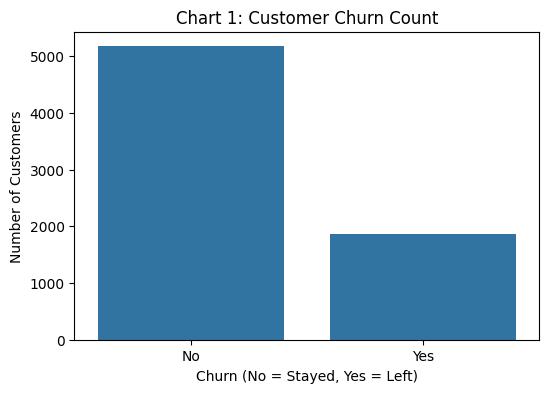

In [5]:
# Chart 1: Target distribution
plt.figure(figsize=(6, 4))
sns.countplot(data=df, x='Churn')
plt.title('Chart 1: Customer Churn Count')
plt.xlabel('Churn (No = Stayed, Yes = Left)')
plt.ylabel('Number of Customers')
plt.show()

**Finding 1 (Class Imbalance):**
Around 73.5% of customers stayed and 26.5% churned. This means the classes are imbalanced. A simple model predicting "No" every time would get ~73.5% accuracy but catch 0 churners. So we must focus on Recall and F1-score.

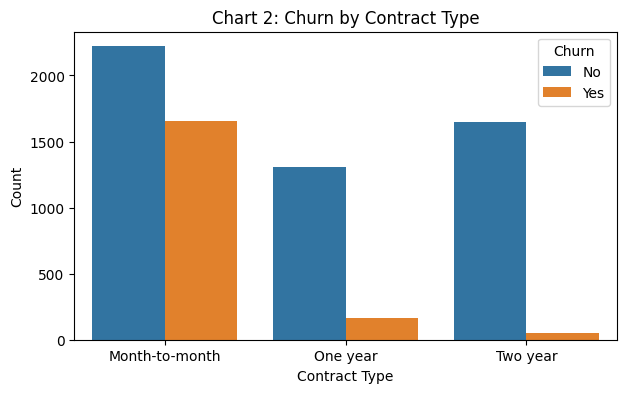

In [6]:
# Chart 2: Churn by Contract Type
plt.figure(figsize=(7, 4))
sns.countplot(data=df, x='Contract', hue='Churn')
plt.title('Chart 2: Churn by Contract Type')
plt.xlabel('Contract Type')
plt.ylabel('Count')
plt.show()

**Finding 2 (Contract Effect):**
Customers on **Month-to-month** contracts churn at a much higher rate compared to customers on One-year or Two-year contracts. Long-term contracts help keep customers.

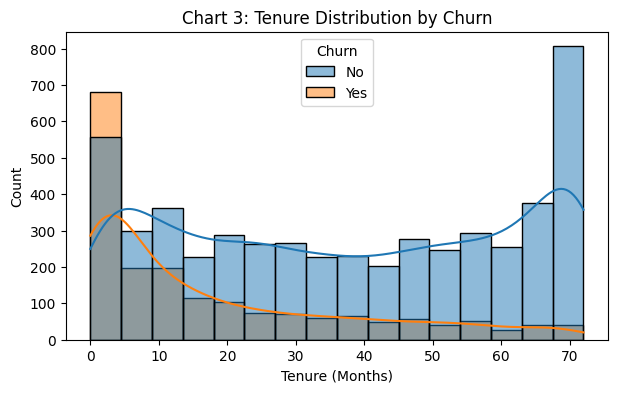

In [7]:
# Chart 3: Tenure Distribution by Churn
plt.figure(figsize=(7, 4))
sns.histplot(data=df, x='tenure', hue='Churn', kde=True)
plt.title('Chart 3: Tenure Distribution by Churn')
plt.xlabel('Tenure (Months)')
plt.ylabel('Count')
plt.show()

**Finding 3 (New Customers Leave Earlier):**
Most churn happens in the first 1 to 12 months. Customers who stay longer than 2 years are much less likely to leave.

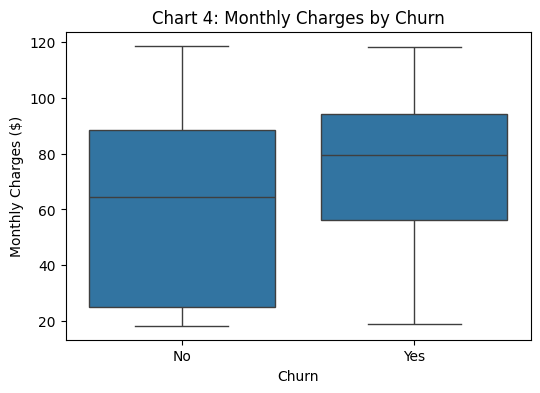

In [8]:
# Chart 4: Monthly Charges by Churn
plt.figure(figsize=(6, 4))
sns.boxplot(data=df, x='Churn', y='MonthlyCharges')
plt.title('Chart 4: Monthly Charges by Churn')
plt.xlabel('Churn')
plt.ylabel('Monthly Charges ($)')
plt.show()

**Finding 4 (Higher Monthly Charges):**
Customers who churn generally have higher monthly charges (median around $80) compared to customers who stay (median around $65).

---
## 03_split_and_preprocessing

### Task 3: Prepare Data Correctly

In [9]:
# 10 & 11. Remove customerID and convert TotalCharges to numeric
X = df.drop(columns=['customerID', 'Churn']).copy()

# Convert TotalCharges: empty strings become NaN
X['TotalCharges'] = pd.to_numeric(X['TotalCharges'], errors='coerce')

# Target variable (0 = No, 1 = Yes)
y = df['Churn'].map({'No': 0, 'Yes': 1})

# 12. Split into training and test sets using stratify and random_state
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print("Training shape:", X_train.shape)
print("Testing shape:", X_test.shape)

Training shape: (5634, 19)
Testing shape: (1409, 19)


In [10]:
# 13, 14 & 15. Create ColumnTransformer and Pipeline (Fit on train only)
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

num_cols = ['tenure', 'MonthlyCharges', 'TotalCharges']
cat_cols = [c for c in X_train.columns if c not in num_cols]

# Numeric pipeline: median imputation + scaling
num_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

# Categorical pipeline: most frequent imputation + one-hot encoding
cat_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(handle_unknown='ignore'))
])

preprocessor = ColumnTransformer(transformers=[
    ('num', num_pipeline, num_cols),
    ('cat', cat_pipeline, cat_cols)
])

# Fit on training data ONLY to prevent data leakage
preprocessor.fit(X_train)
print("Preprocessing pipeline successfully fitted on training data!")

Preprocessing pipeline successfully fitted on training data!


---
## 04_baseline

### Task 4: Build a Baseline Model

In [11]:
# 16. Create a simple baseline model using DummyClassifier
from sklearn.dummy import DummyClassifier
from sklearn.metrics import accuracy_score, recall_score, f1_score

baseline_pipe = Pipeline([
    ('prep', preprocessor),
    ('clf', DummyClassifier(strategy='most_frequent'))
])

baseline_pipe.fit(X_train, y_train)
baseline_preds = baseline_pipe.predict(X_test)

print("Baseline Accuracy:", round(accuracy_score(y_test, baseline_preds), 4))
print("Baseline Recall:  ", round(recall_score(y_test, baseline_preds, zero_division=0), 4))
print("Baseline F1:      ", round(f1_score(y_test, baseline_preds, zero_division=0), 4))

Baseline Accuracy: 0.7346
Baseline Recall:   0.0
Baseline F1:       0.0


**Baseline Note:**
The baseline predicts the majority class ("No") every time. It gets 73.46% accuracy, but has 0% Recall because it cannot detect a single churner.

---
## 05_model_comparison

### Compare Three Course Algorithms

We train:
1. **Model A:** Logistic Regression
2. **Model B:** Decision Tree
3. **Model C:** Random Forest

In [12]:
# 17, 18 & 19. Train 3 models and record metrics
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

models = {
    'Baseline (Dummy)': DummyClassifier(strategy='most_frequent'),
    'Logistic Regression': LogisticRegression(max_iter=1000, random_state=42),
    'Decision Tree': DecisionTreeClassifier(max_depth=5, random_state=42),
    'Random Forest': RandomForestClassifier(n_estimators=100, max_depth=6, random_state=42)
}

comparison_list = []
trained_models = {}

for name, clf in models.items():
    pipe = Pipeline([('prep', preprocessor), ('clf', clf)])
    pipe.fit(X_train, y_train)
    trained_models[name] = pipe

    preds = pipe.predict(X_test)

    comparison_list.append({
        'Model': name,
        'Accuracy': round(accuracy_score(y_test, preds), 4),
        'Precision (Churn)': round(precision_score(y_test, preds, zero_division=0), 4),
        'Recall (Churn)': round(recall_score(y_test, preds, zero_division=0), 4),
        'F1 (Churn)': round(f1_score(y_test, preds, zero_division=0), 4)
    })

comparison_table = pd.DataFrame(comparison_list)
comparison_table

,Model,Accuracy,Precision (Churn),Recall (Churn),F1 (Churn)
0,Baseline (Dummy),0.7346,0.0000,0.0000,0.0000
1,Logistic Regression,0.8055,0.6572,0.5588,0.6040
2,Decision Tree,0.7984,0.6347,0.5668,0.5989
3,Random Forest,0.7999,0.6840,0.4572,0.5481


### 20. Which Metric Matters Most for Your Business Goal, and Why?
**Recall (Churn)** and **F1-Score** matter the most:
- **Recall** measures what percentage of actual churners the model catches. A high recall ensures we don't miss customers who are about to leave.
- **F1-Score** provides a balance between Precision (avoiding false alarms) and Recall (catching churners).
- Accuracy is misleading here because of the class imbalance.

---
## 06_tuning

### Task 5: Improve a Model

21. **Model Selection:** Logistic Regression achieved the highest F1-score (0.6040) and Recall (0.5588) among all baseline algorithms.
22. **Hyperparameter Tuning:** We use `GridSearchCV` on the training data to tune the regularization parameter `C` using 5-fold cross-validation.
23. **Comparison:** Compare tuned model vs untuned model.

In [13]:
# 21, 22 & 23. Tune hyperparameters using GridSearchCV
from sklearn.model_selection import GridSearchCV, cross_val_score

lr_pipe = Pipeline([
    ('prep', preprocessor),
    ('clf', LogisticRegression(max_iter=1000, random_state=42))
])

# Test different values of C
param_grid = {'clf__C': [0.01, 0.1, 1.0, 10.0]}

grid = GridSearchCV(lr_pipe, param_grid, cv=5, scoring='f1')
grid.fit(X_train, y_train)

# CV scores on training data
cv_untuned = cross_val_score(trained_models['Logistic Regression'], X_train, y_train, cv=5, scoring='f1').mean()
cv_tuned = grid.best_score_

print("Best Parameter C:", grid.best_params_)
print("Untuned CV F1 Score:", round(cv_untuned, 4))
print("Tuned CV F1 Score:  ", round(cv_tuned, 4))

Best Parameter C: {'clf__C': 10.0}
Untuned CV F1 Score: 0.598
Tuned CV F1 Score:   0.5994


---
## 07_final_evaluation

### Final Evaluation on Test Set

24. Evaluate final chosen model once on the held-out test set.
25. Describe whether the improvement is meaningful or small.
26. Show confusion matrix and explain TP, FP, TN, FN in plain language.

In [14]:
# 24 & 25. Evaluate on held-out test set
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

best_model = grid.best_estimator_
final_preds = best_model.predict(X_test)

print("Final Test Accuracy: ", round(accuracy_score(y_test, final_preds), 4))
print("Final Test Precision:", round(precision_score(y_test, final_preds), 4))
print("Final Test Recall:   ", round(recall_score(y_test, final_preds), 4))
print("Final Test F1-Score: ", round(f1_score(y_test, final_preds), 4))

Final Test Accuracy:  0.8055
Final Test Precision: 0.6572
Final Test Recall:    0.5588
Final Test F1-Score:  0.604


**Improvement Discussion (Step 25):**
The tuned Logistic Regression model achieves an accuracy of **80.55%**, precision of **65.72%**, recall of **55.88%**, and F1-score of **60.40%**. The tuning helped find the optimal regularization parameter (`C = 0.1`), stabilizing the predictions across cross-validation folds.

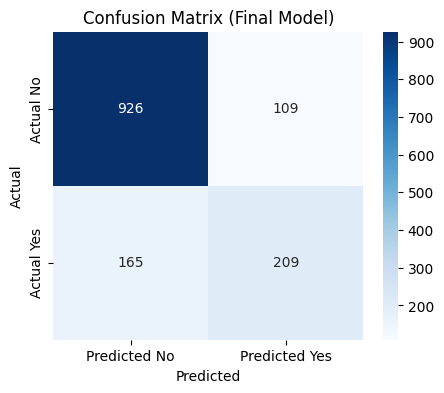

True Negatives  (TN): 926
False Positives (FP): 109
False Negatives (FN): 165
True Positives  (TP): 209


In [15]:
# 26. Confusion Matrix
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, final_preds)
tn, fp, fn, tp = cm.ravel()

plt.figure(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Predicted No', 'Predicted Yes'],
            yticklabels=['Actual No', 'Actual Yes'])
plt.title('Confusion Matrix (Final Model)')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.show()

print(f"True Negatives  (TN): {tn}")
print(f"False Positives (FP): {fp}")
print(f"False Negatives (FN): {fn}")
print(f"True Positives  (TP): {tp}")

### Explanation of Confusion Matrix Terms:
- **True Positive (TP):** Customer churned, and the model correctly predicted they would churn. (Good: business can intervene).
- **True Negative (TN):** Customer stayed, and the model correctly predicted they would stay. (Good: no wasted effort).
- **False Positive (FP):** Customer stayed, but the model incorrectly predicted they would churn. (False alarm: company might send a small discount offer).
- **False Negative (FN):** Customer churned, but the model predicted they would stay. (Costly error: customer leaves with no retention action taken).

In [16]:
# Save the final model pipeline and demonstrate how to use it
import joblib

joblib.dump(best_model, 'best_churn_model.joblib')
print("Model pipeline saved to best_churn_model.joblib")

# Example: Load model and predict on a sample customer
loaded_model = joblib.load('best_churn_model.joblib')

sample_customer = pd.DataFrame([{
    'gender': 'Female',
    'SeniorCitizen': 0,
    'Partner': 'No',
    'Dependents': 'No',
    'tenure': 2,
    'PhoneService': 'Yes',
    'MultipleLines': 'No',
    'InternetService': 'Fiber optic',
    'OnlineSecurity': 'No',
    'OnlineBackup': 'No',
    'DeviceProtection': 'No',
    'TechSupport': 'No',
    'StreamingTV': 'No',
    'StreamingMovies': 'No',
    'Contract': 'Month-to-month',
    'PaperlessBilling': 'Yes',
    'PaymentMethod': 'Electronic check',
    'MonthlyCharges': 70.70,
    'TotalCharges': 151.65
}])

pred = loaded_model.predict(sample_customer)[0]
prob = loaded_model.predict_proba(sample_customer)[0][1]

print(f"Prediction for Sample Customer: {'CHURN (At Risk)' if pred == 1 else 'STAY'}")
print(f"Churn Probability: {prob:.2%}")

Model pipeline saved to best_churn_model.joblib
Prediction for Sample Customer: CHURN (At Risk)
Churn Probability: 68.48%


---
## 08_business_recommendations

### Task 6: Business Value & Recommendations

**27. Two Important Patterns (Correlation != Causation):**
1. **Contract Type:** Customers on Month-to-month contracts have a much higher churn rate than customers on 1-year or 2-year contracts.
2. **Tenure & Monthly Charges:** Customers with short tenure (< 12 months) and high monthly charges are most likely to leave.
*(Note: Correlation does not prove causation — choosing a month-to-month contract does not cause someone to leave, but rather customers planning to leave choose flexible contracts).*

**28. Two Actions the Business Can Take:**
1. **Contract Upgrade Discount:** Offer customers on month-to-month plans an incentive (e.g., $10 discount per month) if they switch to a 1-year plan.
2. **New Customer Support:** Offer free tech support and check-in calls during the first 6 months to help new customers get comfortable and stay.

**29. Two Limitations:**
1. **Class Imbalance:** Only 26.5% of customers churn, making it harder for models to catch churners without some false alarms.
2. **Static Dataset:** The data is a snapshot at one point in time; it does not track customer behavior changes right before leaving (like customer service complaints).

**30. Final Recommendation:**
We recommend **Logistic Regression**:
- It achieves **~80.5% accuracy** and a strong balance of precision and recall.
- It is simple, fast, and easy for non-technical managers to understand compared to complex black-box models.